# **ML 시각화 - seaborn**
* matplotlib : https://matplotlib.org/stable/ , https://wikidocs.net/book/5011
* seaborn : https://seaborn.pydata.org/
* plotly : https://plotly.com
* folium : https://python-visualization.github.io/folium/latest/
* <b>pip install matplotlib, seaborn, plotly, folium

> matplotlib : 가장 일반적인 시각화 <br>
seaborn : matplotlib + 통계 <br>
plotly : 웹 연동 동적 시각화 <br>
folium : GIS 지도 시각화

In [17]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

#인증서 해제 명령어
import ssl
ssl._create_default_https_context = ssl._create_unverified_context

sns.set()

#-------------------- 차트 관련 속성 (한글처리, 그리드) -----------
plt.rcParams['font.family']= 'Malgun Gothic'
plt.rcParams['axes.unicode_minus'] = False



# import ssl
# ssl._create_default_https_context = ssl._create_unverified_context

In [18]:
df = sns.load_dataset("penguins")
df.head()

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,Male
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,Female
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,Female
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,Female


In [19]:
df['species'].value_counts()

species
Adelie       152
Gentoo       124
Chinstrap     68
Name: count, dtype: int64

# 라인 : plt.plot() vs. sns.lineplot()

In [20]:
df = sns.load_dataset("fmri")
df.head(3)

,subject,timepoint,event,region,signal
0,s13,18,stim,parietal,-0.017552
1,s5,14,stim,parietal,-0.080883
2,s12,18,stim,parietal,-0.081033


In [21]:
df['region'].value_counts()

region
parietal    532
frontal     532
Name: count, dtype: int64

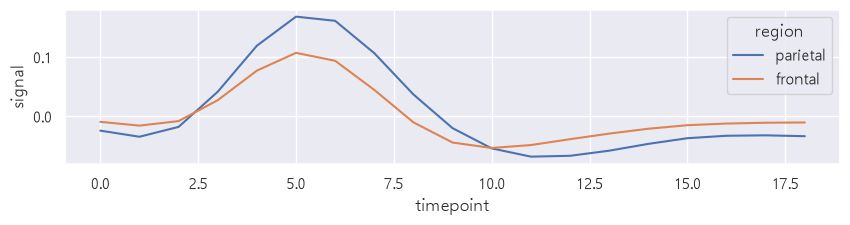

In [22]:
plt.figure(figsize=(10, 2))
sns.lineplot(x="timepoint", y="signal", data=df, hue="region", errorbar=None)  #errorbar=('ci', 95)
plt.show()

# 바 : plt.bar() vs. sns.barplot()

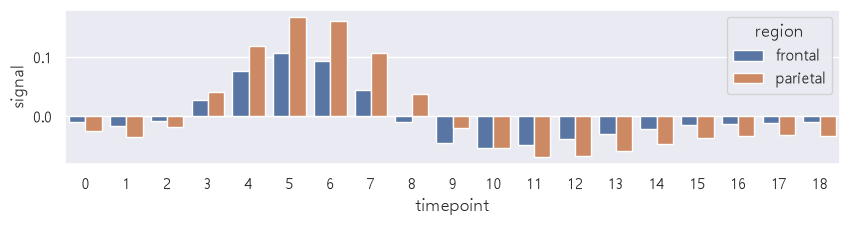

In [23]:
plt.figure(figsize=(10, 2))
sns.barplot(x="timepoint", y="signal", data=df, hue="region", errorbar=None)  #errorbar=('ci', 95)
plt.show()

# 스캐터 : plt.scatter() vs. sns.scatterplot()

In [24]:
df = sns.load_dataset("diamonds")
df.head(2)

,carat,cut,color,clarity,depth,table,price,x,y,z
0,0.23,Ideal,E,SI2,61.5,55.0,326,3.95,3.98,2.43
1,0.21,Premium,E,SI1,59.8,61.0,326,3.89,3.84,2.31


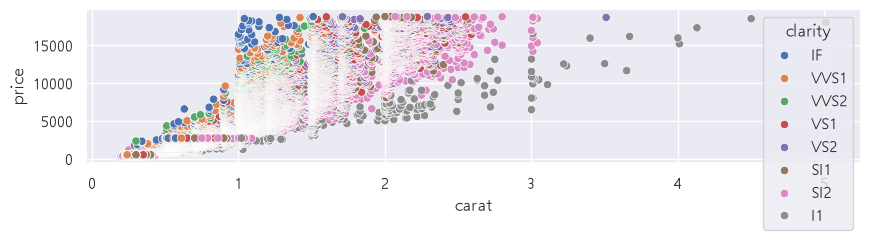

In [25]:
plt.figure(figsize=(10, 2))
df = sns.load_dataset("diamonds")
sns.scatterplot(x="carat", y="price",hue="clarity", data=df)
plt.show()

# 히트맵

In [35]:
df = sns.load_dataset("flights")
df.head(3)

,year,month,passengers
0,1949,Jan,112
1,1949,Feb,118
2,1949,Mar,132


In [38]:
dfpv = df.pivot(index="month", columns="year", values="passengers") #이 데이타는 dfpv의 피벗으로 임의 정의

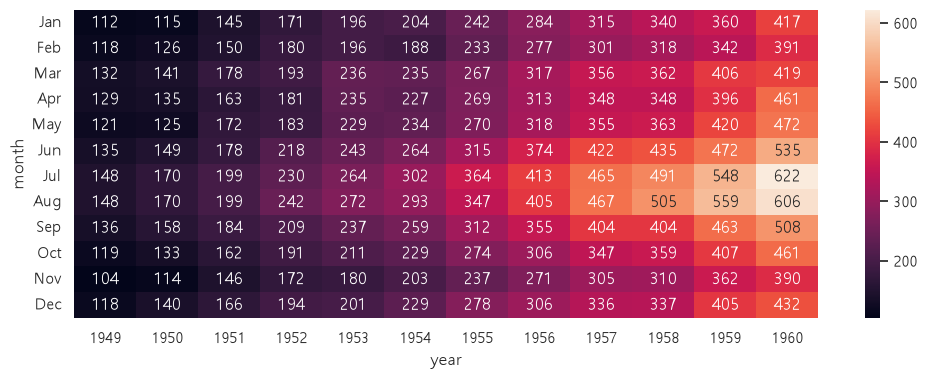

In [41]:
plt.figure(figsize=(12, 4))
sns.heatmap(dfpv, annot=True, fmt="d")
plt.show()

# 히스토그램 : plt.hist() vs. sns.histplot()

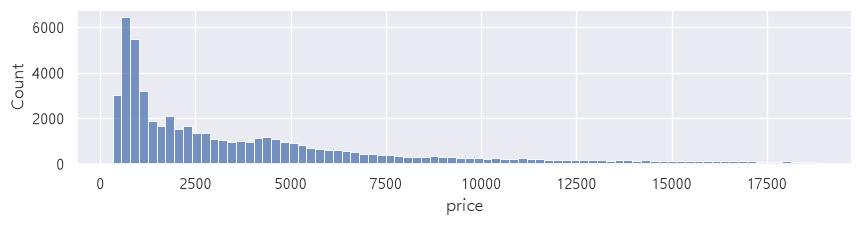

In [26]:
plt.figure(figsize=(10, 2))
df = sns.load_dataset("diamonds")
sns.histplot(x="price", data=df) #, hue="clarity")
plt.show()

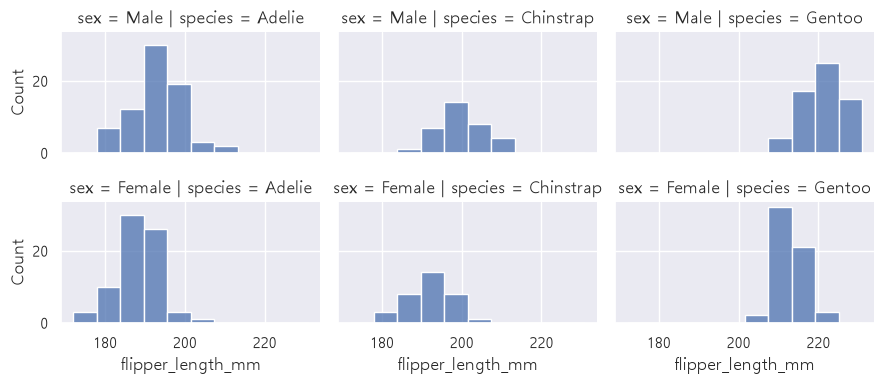

In [27]:
###### plt.figure(figsize=(10, 2))
df = sns.load_dataset("penguins")
sns.displot(x="flipper_length_mm", col="species", row="sex", data=df,  height=2, aspect=1.5)
plt.show()

# 박스플롯 : plt.boxplot() vs. sns.boxplot()

In [28]:
df = sns.load_dataset("tips")
df.head(2)

,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3


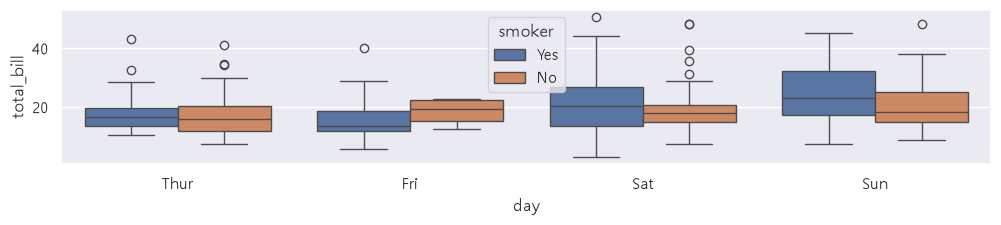

In [29]:
plt.figure(figsize=(12, 2))
sns.boxplot(x="day", y="total_bill", hue="smoker", data=df)
plt.show()

# 바이올린플롯 : plt.violinplot() vs. sns.violinplot()

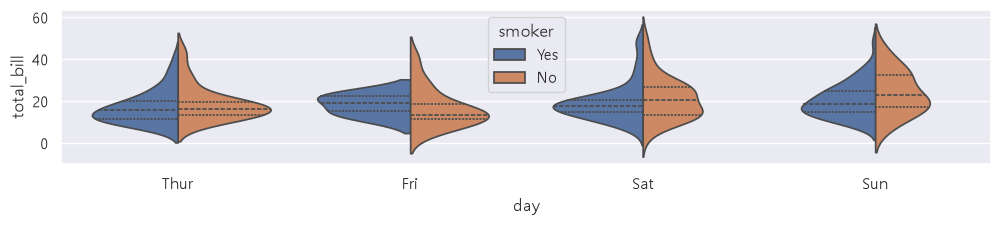

In [30]:
plt.figure(figsize=(12, 2))
sns.violinplot(data=df, x="day", y="total_bill", hue="smoker"        , split=True, inner="quart")
plt.show()

# 복합차트 예 : sns.pairplot()

In [33]:
df = sns.load_dataset("tips")
df.head()


,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4


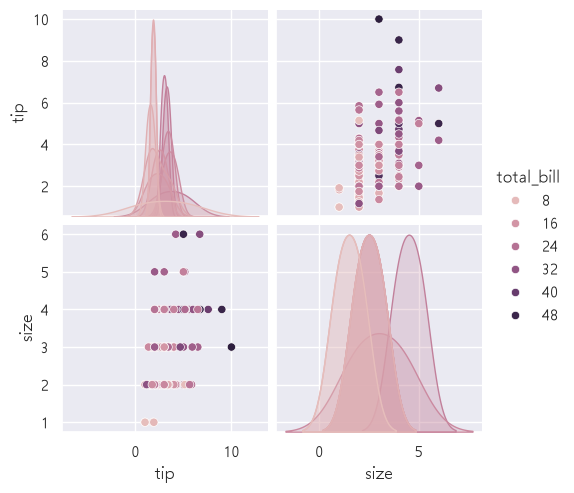

In [34]:
sns.pairplot(df, hue="total_bill")  #,   height=1)
plt.show()